In [1]:
import pandas as pd
import numpy as np

train_df = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [2]:
X_train = train_df.drop(columns=["id", "attack_cat", "label"])
X_test = test_df.drop(columns=["id", "attack_cat", "label"])

y_train = train_df["label"]
y_test = test_df["label"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (175341, 42)
X_test: (82332, 42)
y_train: (175341,)
y_test: (82332,)


In [3]:
categorical_features = ["proto", "service", "state"]

numeric_features = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))
print("Total features:", len(categorical_features) + len(numeric_features))

Categorical features: ['proto', 'service', 'state']
Number of numeric features: 39
Total features: 42


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [5]:
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Binary baseline model created successfully!")

Binary baseline model created successfully!


In [6]:
baseline_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [7]:
y_pred = baseline_model.predict(X_test)

y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Total predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10])

Total predictions: 82332
First 10 predictions: [1 1 1 1 1 1 1 1 0 0]


In [8]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9476    0.6102    0.7424     37000
           1     0.7535    0.9724    0.8491     45332

    accuracy                         0.8097     82332
   macro avg     0.8505    0.7913    0.7957     82332
weighted avg     0.8407    0.8097    0.8011     82332



In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(cm)

[[22579 14421]
 [ 1249 44083]]


In [10]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, average_precision_score

print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Average Precision:", average_precision_score(y_test, y_prob))

Balanced Accuracy: 0.7913454811469017
ROC-AUC: 0.9556235753754285
Average Precision: 0.9661102725652112


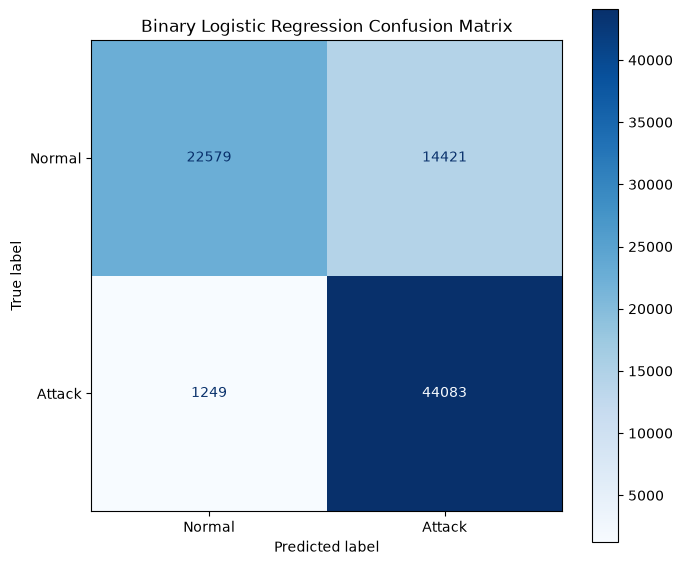

Confusion matrix saved successfully!


In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("Binary Logistic Regression Confusion Matrix")

fig.tight_layout()
fig.savefig(output_dir / "binary_confusion_matrix.png", dpi=300)

plt.show()

print("Confusion matrix saved successfully!")

In [12]:
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = pd.DataFrame([{
    "model": "Logistic Regression",
    "task": "Binary",
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "attack_precision": precision_score(y_test, y_pred),
    "attack_recall": recall_score(y_test, y_pred),
    "normal_recall": recall_score(y_test, y_pred, pos_label=0),
    "roc_auc": roc_auc_score(y_test, y_prob),
    "average_precision": average_precision_score(y_test, y_prob)
}])

output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    output_dir / "binary_baseline_metrics.csv",
    index=False
)

print("Baseline metrics saved successfully!")
print(results.round(4).to_string(index=False))

Baseline metrics saved successfully!
              model   task  accuracy  macro_f1  balanced_accuracy  attack_precision  attack_recall  normal_recall  roc_auc  average_precision
Logistic Regression Binary    0.8097    0.7957             0.7913            0.7535         0.9724         0.6102   0.9556             0.9661
